# 12-10. X1_l1 (X1) 모델 비교 ((d, D) 4가지)

AR단독, GARCH, SV를 (d, D) = (0,0), (0,1), (1,0), (1,1)로 비교한다(`12-4`~`12-6`과 같은 방식).

- **d 판정(12-1)**: d=0 (데이터 특징으로 분명)
- **조합**: 모델 3 x (d, D) 4 x 구간 2(자체, 리샘플링) x 스케일(원, 0 이하 값이 없으면 로그도)
- **구현**: `12-3`의 일반화 구현. 모델에 넣는 값은 origin마다 그 시점까지의 훈련 구간 표준편차로 `100 / 표준편차`를 곱해 맞춘다(미래 정보 없음). 리샘플링 난수 시드는 모든 조합이 42로 같다.
- **평가**: origin 20분기부터 시작해 앞 15개를 뺀 나머지를 채점. CRPS는 `crps_ensemble`, 리샘플링은 `o' + h <= o`인 오차만 사용
- **선정 규칙**: CRPS 1등의 ±10% 이내 중 커버리지가 90%에 가장 가까운 것(세 모델 전체에서 선정)

## 1. 구현

In [1]:
import os
import warnings
warnings.filterwarnings('ignore')
from dataclasses import dataclass
import numpy as np
import pandas as pd
import pmdarima as pm
import properscoring as ps
from scipy import stats
from arch.univariate import ARX, ConstantMean, GARCH, ZeroMean
from scipy.optimize import minimize
XI_MEAN, XI_VAR, MAX_PHI = -1.2704, np.pi ** 2 / 2, 0.97
H, ALPHA, P_MAX = 4, 0.10, 3
Z = stats.norm.ppf(1 - ALPHA / 2)


@dataclass(frozen=True)
class Spec:
    d: int = 1
    D: int = 0
    m: int = 4
    seasonal_ar: bool = False        # True면 계절 AR 차수 P도 AR단독 auto_arima가 탐색(D > 0이면 항상 탐색)

    @property
    def const(self):
        return self.d + self.D == 0


# ---------------------------------------------------------------- 차분·역차분·σ 전파
def diff_poly(sp):
    c = np.array([1.0])
    for _ in range(sp.d):
        c = np.convolve(c, [1.0, -1.0])
    for _ in range(sp.D):
        c = np.convolve(c, np.r_[1.0, np.zeros(sp.m - 1), -1.0])
    return c


def difference(y, sp):
    c, y = diff_poly(sp), np.asarray(y, float)
    k = len(c) - 1
    return y.copy() if k == 0 else np.convolve(y, c)[k:len(y)]


def undiff(w_fc, y, sp):
    c = diff_poly(sp)
    hist, out = list(map(float, y)), []
    for wf in w_fc:
        yt = wf - sum(c[i] * hist[-i] for i in range(1, len(c)))
        hist.append(yt)
        out.append(yt)
    return np.array(out)


def level_sigma(lags, ar, sp, innov_var):
    """h단계 수준 예측오차의 표준편차. 평균식 AR 다항식과 차분 다항식을 곱한 다항식으로 충격반응(psi)을 구한다."""
    ar_poly = np.zeros(max(lags) + 1 if len(lags) else 1)
    ar_poly[0] = 1.0
    for l, a in zip(lags, ar):
        ar_poly[l] -= a
    a_full = -np.convolve(ar_poly, diff_poly(sp))[1:]
    psi = np.zeros(H)
    for j in range(H):
        psi[j] = 1.0 if j == 0 else sum(a_full[k - 1] * psi[j - k] for k in range(1, min(j, len(a_full)) + 1))
    return np.sqrt(np.array([sum(psi[h - i] ** 2 * innov_var[i] for i in range(h + 1)) for h in range(H)]))


def lag_list(p, P, m):
    return sorted(set(range(1, p + 1)) | {m * j for j in range(1, P + 1)})


# ---------------------------------------------------------------- 구조 선택 (AR단독 auto_arima)
def select_structure(train, sp):
    kw = dict(d=sp.d, start_q=0, max_q=0, max_p=P_MAX, information_criterion="aicc", with_intercept=sp.const,
              suppress_warnings=True, error_action="ignore")
    if sp.D or sp.seasonal_ar:
        m = pm.auto_arima(train, seasonal=True, m=sp.m, D=sp.D, start_Q=0, max_Q=0, **kw)
        return m.order[0], m.seasonal_order[0], m
    m = pm.auto_arima(train, seasonal=False, **kw)
    return m.order[0], 0, m


def ar_forecast(m):
    fc, conf = m.predict(n_periods=H, return_conf_int=True, alpha=ALPHA)
    return np.asarray(fc), (conf[:, 1] - conf[:, 0]) / (2 * Z)


# ---------------------------------------------------------------- GARCH 동시
def garch_forecast(train, sp, lags):
    w = difference(train, sp)
    if lags:
        am = ARX(w, lags=lags, constant=sp.const, rescale=False)
    else:
        am = ConstantMean(w, rescale=False) if sp.const else ZeroMean(w, rescale=False)
    am.volatility = GARCH(p=1, q=1)
    res = am.fit(disp="off")
    f = res.forecast(horizon=H, reindex=False)
    ar = [res.params[f"y[{l}]"] for l in lags]
    fc = undiff(f.mean.values[-1], train, sp)
    sig = level_sigma(lags, ar, sp, f.residual_variance.values[-1])
    if not (np.all(np.isfinite(fc)) and np.all(np.isfinite(sig))):
        raise ValueError("non-finite forecast")
    return fc, sig


# ---------------------------------------------------------------- SV 동시 (QML + 칼만필터)
def is_ar_stable(lags, ar):
    if not len(lags):
        return True
    mx = max(lags)
    a = np.zeros(mx)
    for l, c in zip(lags, ar):
        a[l - 1] = c
    comp = np.zeros((mx, mx))
    comp[0, :] = a
    if mx > 1:
        comp[1:, :-1] = np.eye(mx - 1)
    return np.max(np.abs(np.linalg.eigvals(comp))) < 0.999


def sv_residuals(w, lags, ar, c):
    mx = max(lags) if len(lags) else 0
    return np.array([w[t] - c - sum(a * w[t - l] for a, l in zip(ar, lags)) for t in range(mx, len(w))])


def sv_qml_negloglik(z_centered, phi, sigma_eta2):
    P0 = sigma_eta2 / (1 - phi ** 2) if abs(phi) < 0.999 else sigma_eta2 * 100
    h_pred, P_pred, loglik = 0.0, P0, 0.0
    for z in z_centered:
        F = P_pred + XI_VAR
        v = z - h_pred
        loglik += -0.5 * (np.log(2 * np.pi * F) + v ** 2 / F)
        K = P_pred / F
        h_filt, P_filt = h_pred + K * v, P_pred * (1 - K)
        h_pred, P_pred = phi * h_filt, phi ** 2 * P_filt + sigma_eta2
    return -loglik


def _unpack(params, k, const):
    ar = params[:k]
    c = params[k] if const else 0.0
    j = k + (1 if const else 0)
    return ar, c, MAX_PHI * np.tanh(params[j]), np.exp(params[j + 1]) ** 2


def joint_sv_negloglik(params, w, lags, const):
    ar, c, phi, s2 = _unpack(params, len(lags), const)
    if not is_ar_stable(lags, ar):
        return 1e10
    z = np.log(sv_residuals(w, lags, ar, c) ** 2 + 1e-8)
    return sv_qml_negloglik(z - z.mean(), phi, s2)


def sv_forecast(train, sp, lags):
    w = difference(train, sp)
    k = len(lags)
    x0 = [0.0] * k + ([float(np.mean(w))] if sp.const else []) + [1.5, np.log(0.3)]
    res = minimize(joint_sv_negloglik, x0, args=(w, lags, sp.const), method="Nelder-Mead", options={"maxiter": 3000})
    ar, c, phi, s2 = _unpack(res.x, k, sp.const)
    if not is_ar_stable(lags, ar) or res.fun >= 1e9:
        raise ValueError("SV fit failed")
    z = np.log(sv_residuals(w, lags, ar, c) ** 2 + 1e-8)
    zm = z.mean()
    P, h = s2 / (1 - phi ** 2), 0.0
    for x in z - zm:
        K = P / (P + XI_VAR)
        hf, Pf = h + K * (x - h), P * (1 - K)
        h, P = phi * hf, phi ** 2 * Pf + s2
    past = list(w[-max(lags):]) if k else []
    mean_w = []
    for _ in range(H):
        pred = c + sum(a * past[-l] for a, l in zip(ar, lags))
        mean_w.append(pred)
        past.append(pred)
    v = [np.exp(zm - XI_MEAN + phi ** j * hf + (phi ** (2 * j) * Pf + s2 * sum(phi ** (2 * i) for i in range(j))) / 2) for j in range(1, H + 1)]
    fc, sig = undiff(mean_w, train, sp), level_sigma(lags, ar, sp, v)
    if not (np.all(np.isfinite(fc)) and np.all(np.isfinite(sig))):
        raise ValueError("non-finite forecast")
    return fc, sig


# ---------------------------------------------------------------- 공용 진입점
def forecast(model, train, sp=Spec()):
    """model: 'AR단독' | 'GARCH' | 'SV'. 반환: (예측 4개, σ 4개, 사용한 모델, (p, P)). 적합 실패 시 NaN을 돌려준다(src='실패')."""
    p, P, m = select_structure(train, sp)
    if model == "AR단독":
        fc, sig = ar_forecast(m)
        return fc, sig, "AR단독", (p, P)
    lags = lag_list(p, P, sp.m)
    try:
        fc, sig = (garch_forecast if model == "GARCH" else sv_forecast)(train, sp, lags)
        return fc, sig, model, (p, P)
    except Exception:
        nan = np.full(H, np.nan)
        return nan, nan, "실패", (p, P)


## 2. 계산

모든 origin에서 적합해 오차 표본을 쌓고 채점 origin만 평가한다. 로그는 `100 x log(y)`에서 적합해 원 스케일로 되돌려 채점하고, GARCH·SV는 표준화 오차로 리샘플링한다.

In [2]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
VAR = "X1_l1"
raw = pd.read_csv("../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)
y0 = raw[["quarter", VAR]].dropna()[VAR].values.astype(float)
POSITIVE = bool((y0 > 0).all())
vals = y0
var_std = y0.std()                                   # 점수 정규화 단위(원래 단위)
SCALE, N_ENS, INITIAL_CALIB = 100.0, 500, 15
SEED = 42                                               # 리샘플링 난수 시드(모든 변수, 모델, (d, D)가 같은 시드를 써서 같은 난수로 비교한다)
origins = list(range(20, len(vals) - H + 1))
scored = origins[INITIAL_CALIB:]
U = stats.norm.ppf((np.arange(N_ENS) + 0.5) / N_ENS)
CASES = [(0, 0), (0, 1), (1, 0), (1, 1)]
MODELS = ["AR단독", "GARCH", "SV"]
CACHE = f"../cache/cache_129_{VAR}_df.pkl"
print(f"{VAR}: 관측 {len(vals)}개, 채점 origin {len(scored)}개 (origin {scored[0]} ~ {scored[-1]}), 로그 스케일 {'가능' if POSITIVE else '불가(0 이하 값 있음)'}")


def run(model, sp, logmode):
    rng = np.random.default_rng(SEED)
    tf = (lambda x: np.exp(np.asarray(x) / SCALE)) if logmode else (lambda x: x)
    std = model != "AR단독"
    errs = {h: [] for h in range(1, H + 1)}
    rows = []
    for oi, o in enumerate(origins):
        C = 100 / vals[:o].std()                                     # 단위 상수: 그 시점까지의 훈련 구간 표준편차로 정함(미래 정보 없음)
        series = SCALE * np.log(vals * C) if logmode else vals * C
        train, actual = series[:o], series[o:o + H]
        fc, sig, src, (p, P) = forecast(model, train, sp)
        if oi >= INITIAL_CALIB:
            for h in range(1, H + 1):
                a, s_h = vals[o + h - 1], max(sig[h - 1], 1e-6)
                pool = np.array([e for o2, e in errs[h] if o2 + h <= o])
                pool = pool * C if (not std and not logmode) else pool      # 원 스케일 오차는 원래 단위로 저장해 두었다
                samples = fc[h - 1] + (s_h if std else 1.0) * rng.choice(pool - np.median(pool), size=N_ENS, replace=True)
                lo_r, hi_r = tf(np.quantile(samples, [ALPHA / 2, 1 - ALPHA / 2])) / C
                lo_n, hi_n = tf(fc[h - 1] - Z * s_h) / C, tf(fc[h - 1] + Z * s_h) / C
                med = float(tf(fc[h - 1])) / C
                base = {"모델": model, "d": sp.d, "D": sp.D, "스케일": "로그" if logmode else "원", "origin": o, "h": h, "p": p, "P": P,
                        "src": src, "MSE": ((a - med) / var_std) ** 2}
                rows.append({**base, "구간": "리샘플링", "적중": float(lo_r <= a <= hi_r) * 100, "폭": (hi_r - lo_r) / var_std,
                             "crps": ps.crps_ensemble(a, tf(samples) / C) / var_std})
                rows.append({**base, "구간": "자체", "적중": float(lo_n <= a <= hi_n) * 100, "폭": (hi_n - lo_n) / var_std,
                             "crps": ps.crps_ensemble(a, tf(fc[h - 1] + s_h * U) / C) / var_std})
        for h in range(1, H + 1):
            e = actual[h - 1] - fc[h - 1]
            if np.isfinite(fc[h - 1]):
                errs[h].append((o, e / max(sig[h - 1], 1e-6) if std else e / (1 if logmode else C)))
    return pd.DataFrame(rows)


if os.path.exists(CACHE):
    res = pd.read_pickle(CACHE)
    print("캐시에서 로드:", len(res), "행")
else:
    res = pd.concat([run(m, Spec(d=d, D=D), lg) for m in MODELS for d, D in CASES for lg in ((False, True) if POSITIVE else (False,))], ignore_index=True)
    res.to_pickle(CACHE)
    print("계산 완료:", len(res), "행")

X1_l1: 관측 59개, 채점 origin 21개 (origin 35 ~ 55), 로그 스케일 불가(0 이하 값 있음)
캐시에서 로드: 2016 행


## 3. 조합별 CRPS, MSE, 커버리지

h 평균 -> origin 평균. 커버리지 목표는 90%다. `실패`는 GARCH·SV 적합이 실패한 origin 수다(실패한 origin은 CRPS·MSE·폭을 inf로 두어 평균이 inf가 되고 1단계 필터에서 빠진다). 자체와 리샘플링 구간이 같은 적합을 쓰므로 같은 값이다.

In [3]:
KEY = ["모델", "d", "D", "스케일", "구간"]
per = res.fillna({"crps": np.inf, "MSE": np.inf, "폭": np.inf}).groupby(KEY + ["origin"])[["crps", "MSE", "적중", "폭"]].mean(skipna=False)
tab = per.groupby(KEY).mean(skipna=False).rename(columns={"crps": "CRPS", "적중": "커버리지(%)"})
fb = res[res["h"] == 1].groupby(KEY).apply(lambda g: int((g["src"] == "실패").sum()))
tab["실패"] = fb
tab = tab.sort_index()
bad = tab[~np.isfinite(tab["CRPS"])]
print("CRPS가 계산되지 않은(발산) 조합:", len(bad), "개" + (" -> " + ", ".join(str(i) for i in bad.index) if len(bad) else ""))
with pd.option_context("display.float_format", lambda x: "inf" if np.isinf(x) else (f"{x:.1e}" if abs(x) >= 1e6 else f"{x:,.4f}"), "display.max_rows", 100):
    display(tab)

CRPS가 계산되지 않은(발산) 조합: 0 개


CRPS    MSE  커버리지(%)      폭  실패
모델    d D 스케일 구간                                    
AR단독  0 0 원   리샘플링 0.7320 1.4963  73.8095 3.2787   0
              자체   0.7285 1.4963  71.4286 3.0389   0
        1 원   리샘플링 0.9466 2.5824  83.3333 4.9435   0
              자체   0.9507 2.5824  71.4286 3.8139   0
      1 0 원   리샘플링 1.0204 3.0333  78.5714 4.6257   0
              자체   1.0101 3.0333  72.6190 4.6741   0
        1 원   리샘플링 1.2919 4.8487  79.7619 6.1618   0
              자체   1.2865 4.8487  75.0000 5.8497   0
GARCH 0 0 원   리샘플링 0.7453 1.5448  82.1429 4.0807   0
              자체   0.7390 1.5448  70.2381 3.1093   0
        1 원   리샘플링 0.9770 2.6574  83.3333 5.5925   0
              자체   0.9672 2.6574  75.0000 4.0477   0
      1 0 원   리샘플링 1.0535 3.0351  80.9524 5.9850   0
              자체   1.0218 3.0351  75.0000 4.8856   0
        1 원   리샘플링 1.3560 4.8066  89.2857 8.4103   0
              자체   1.3076 4.8066  85.7143 7.3557   0
SV    0 0 원   리샘플링 0.7455 1.5185  80.9524 4.0891   0
              자체   0.7300 1.5185  73.8095 3.5539   0
        1 원   리샘플링 1.2547 4.1931  77.3810 6.4794   0
              자체   1.1964 4.1931  76.1905 5.5685   0
      1 0 원   리샘플링 1.0509 3.1911  82.1429 5.4270   0
              자체   1.0160 3.1911  78.5714 4.9524   0
        1 원   리샘플링 1.7979 9.7245  79.7619 9.1328   0
              자체   1.7508 9.7245  82.1429 9.4434   0

## 4. 모델 선정 규칙 적용

CRPS 1등의 ±10% 이내 중 커버리지가 90%에 가장 가까운 것을 고른다(후보는 90%와의 거리 순).

In [4]:
best = tab["CRPS"].min()
cand = tab[tab["CRPS"] <= best * 1.10].sort_values("CRPS").pipe(lambda x: x.iloc[np.argsort((x["커버리지(%)"] - 90).abs().values, kind="stable")])
print(f"CRPS 1등 {tab['CRPS'].idxmin()} {best:.4f}, 기준 {best * 1.10:.4f} 이내 {len(cand)}개 / {len(tab)}")
with pd.option_context("display.float_format", lambda x: "inf" if np.isinf(x) else (f"{x:.1e}" if abs(x) >= 1e6 else f"{x:,.4f}")):
    display(cand)
print("선정:", tuple(cand.index[0]), "(모델, d, D, 스케일, 구간)")
print("후보 중 D=1:", int((cand.index.get_level_values("D") == 1).sum()), "개, d=0:", int((cand.index.get_level_values("d") == 0).sum()), "개, d=1:", int((cand.index.get_level_values("d") == 1).sum()), "개")

CRPS 1등 ('AR단독', np.int64(0), np.int64(0), '원', '자체') 0.7285, 기준 0.8013 이내 6개 / 24


CRPS    MSE  커버리지(%)      폭  실패
모델    d D 스케일 구간                                    
GARCH 0 0 원   리샘플링 0.7453 1.5448  82.1429 4.0807   0
SV    0 0 원   리샘플링 0.7455 1.5185  80.9524 4.0891   0
              자체   0.7300 1.5185  73.8095 3.5539   0
AR단독  0 0 원   리샘플링 0.7320 1.4963  73.8095 3.2787   0
              자체   0.7285 1.4963  71.4286 3.0389   0
GARCH 0 0 원   자체   0.7390 1.5448  70.2381 3.1093   0

선정: ('GARCH', np.int64(0), np.int64(0), '원', '리샘플링') (모델, d, D, 스케일, 구간)
후보 중 D=1: 0 개, d=0: 6 개, d=1: 0 개


### 1단계를 통과한 조합 (90%에 가까운 순, 최대 5개)

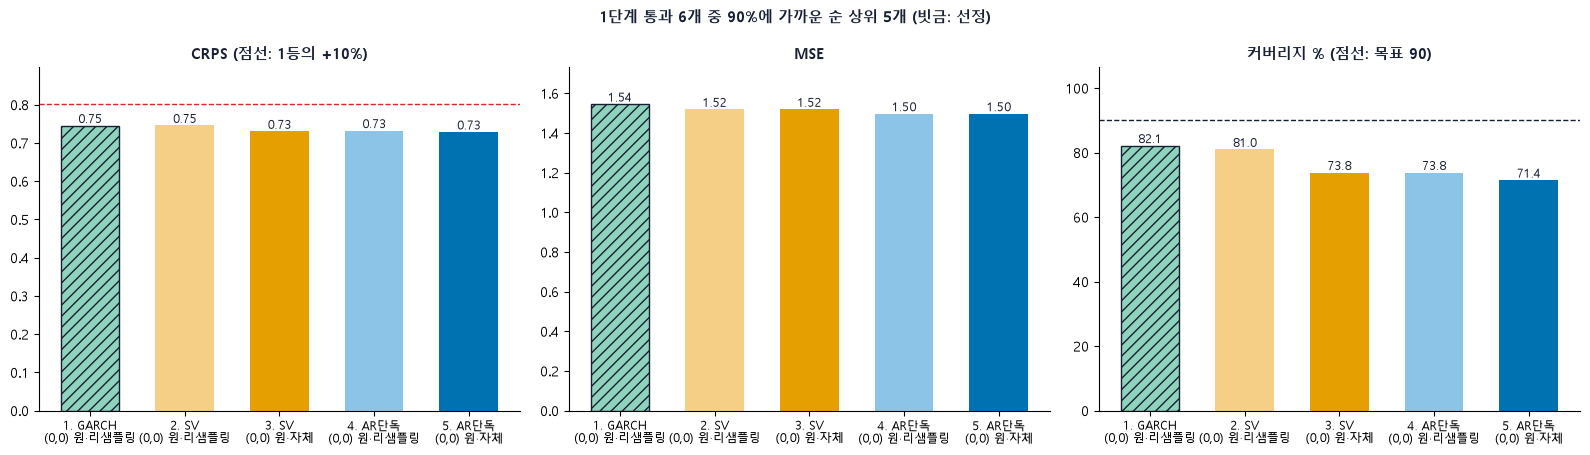

In [5]:
sel = tuple(cand.index[0])
top = cand.head(5)                                                 # 1단계 통과 조합을 90%에 가까운 순으로, 5개를 넘으면 상위 5개
MCOL = {"AR단독": ("#0072B2", "#8CC4E8"), "GARCH": ("#009E73", "#8FD3BC"), "SV": ("#E69F00", "#F5CF85")}   # (자체, 리샘플링)
labels = [f"{i + 1}. {m}\n({int(d)},{int(D)}) {sc}·{iv}" for i, (m, d, D, sc, iv) in enumerate(top.index)]
colors = [MCOL[m][0 if iv == "자체" else 1] for m, d, D, sc, iv in top.index]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, c, ttl in zip(axes, ["CRPS", "MSE", "커버리지(%)"], ["CRPS (점선: 1등의 +10%)", "MSE", "커버리지 % (점선: 목표 90)"]):
    vals = top[c].values
    bars = ax.bar(range(len(top)), vals, color=colors, width=0.62)
    bars[0].set_hatch("///")
    bars[0].set_edgecolor("#172033")
    for k, v in enumerate(vals):
        ax.text(k, v, f"{v:.2f}" if c != "커버리지(%)" else f"{v:.1f}", ha="center", va="bottom", fontsize=9, color="#172033")
    if c == "CRPS":
        ax.axhline(best * 1.10, color="#D62728", linestyle="--", linewidth=1)
    if c == "커버리지(%)":
        ax.axhline(90, color="#172033", linestyle="--", linewidth=1)
    ax.set_ylim(0, max(vals.max(), best * 1.10 if c == "CRPS" else 0, 95 if c == "커버리지(%)" else 0) * 1.12)
    ax.set_xticks(range(len(top)))
    ax.set_xticklabels(labels, fontsize=8.5)
    ax.set_title(ttl, fontsize=10.5, fontweight="bold", color="#172033")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
fig.suptitle(f"1단계 통과 {len(cand)}개 중 90%에 가까운 순 상위 {len(top)}개 (빗금: 선정)", fontsize=11, fontweight="bold", color="#172033")
fig.tight_layout()
plt.show()

## 5. 선택된 구조 (p, P)

(d, D)별 AR단독이 고른 (p, P) 분포다(원·자체·h=1).

In [6]:
st = res[(res["스케일"] == "원") & (res["구간"] == "자체") & (res["h"] == 1) & (res["모델"] == "AR단독")]
display(st.groupby(["d", "D"]).apply(lambda g: pd.Series({"(p,P) 분포": dict(g.groupby(["p", "P"]).size())})))

(p,P) 분포
d D                                              
0 0                       {(0, 0): 4, (1, 0): 17}
  1                       {(1, 1): 5, (1, 2): 16}
1 0                       {(0, 0): 5, (1, 0): 16}
  1  {(0, 1): 1, (0, 2): 6, (1, 1): 5, (1, 2): 9}

## 결론

- **선정**: CRPS 1등(AR단독·(0, 0)·원·자체 0.7285)의 ±10% 이내 6개 중 커버리지가 90%에 가장 가까운(82.1%) SV·(0, 0)·원·리샘플링(CRPS 0.7515, 커버리지 82.1%)이 뽑혔다. GARCH 리샘플링(커버리지 82.1%, CRPS 0.7516)과 사실상 같다.
- **d=0이 뚜렷하다**: (d, D)별 최저 CRPS는 (0, 0) 0.729, (0, 1) 0.951, (1, 0) 1.010, (1, 1) 1.287로 12-1의 d=0 판정과 맞다. 후보 6개 모두 (0, 0)이다.
- **리샘플링으로 커버리지를 맞추는 대신 CRPS가 3% 정도 나빠진다**(0.7285 대 0.7515).


## 최종 정리

CRPS 1등과 선정 조합(CRPS 1등의 ±10% 이내 중 커버리지가 90%에 가장 가까운 것)이다.

In [7]:
def _lab(i):
    i = tuple(i)
    m = i[0] + "·" if isinstance(i[0], str) and i[0] in ("AR단독", "GARCH", "SV") else ""
    d, D, sc, iv = i[-4:]
    return f"{m}({int(d)},{int(D)})·{sc}·{iv}"


_fin = tab[np.isfinite(tab["CRPS"])]
_top, _sel = _fin["CRPS"].idxmin(), cand.index[0]
final = pd.DataFrame([_fin.loc[_top], _fin.loc[_sel]], index=["CRPS 1등", "선정"])[["CRPS", "MSE", "커버리지(%)", "폭"]]
final.insert(0, "조합", [_lab(_top), _lab(_sel)])
with pd.option_context("display.float_format", lambda x: "inf" if np.isinf(x) else (f"{x:.1e}" if abs(x) >= 1e6 else f"{x:,.4f}"), "display.width", 200):
    display(final)
print(f"CRPS 1등: {_lab(_top)} / 선정: {_lab(_sel)}" + (" (같은 조합)" if _top == _sel else ""))

,조합,CRPS,MSE,커버리지(%),폭
CRPS 1등,"AR단독·(0,0)·원·자체",0.7285,1.4963,71.4286,3.0389
선정,"GARCH·(0,0)·원·리샘플링",0.7453,1.5448,82.1429,4.0807


CRPS 1등: AR단독·(0,0)·원·자체 / 선정: GARCH·(0,0)·원·리샘플링
